# Lab 1 - Zadanie


In [ ]:
!pip install torch torchvision matplotlib

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cpu | urządzenie: cpu


In [ ]:
mean, std = 0.2860, 0.3530
tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_ds = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.39MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 140kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.51MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.0MB/s]

Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 60000 | Test: 10000


## 1. Trenowanie i ocena


In [ ]:
import pandas as pd


def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum / total, correct / total


def train_model(model, epochs=8, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    for _ in range(epochs):
        model.train()
        run_loss = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * yb.numel()
        test_loss, test_acc = evaluate(model, test_dl)
        hist["train_loss"].append(run_loss / len(train_ds))
        hist["test_loss"].append(test_loss)
        hist["test_acc"].append(test_acc)
    return model, hist

## 2. Porównanie architektur


In [ ]:
results = {}


def run(name, model):
    model, hist = train_model(model)
    results[name] = {
        "model": model,
        "hist": hist,
        "params": sum(p.numel() for p in model.parameters()),
        "acc": hist["test_acc"][-1],
    }


torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
run("baza (256, 128)", model)

torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
run("(128,)", model)

torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 512), nn.ReLU(),
    nn.Linear(512, 10),
)
run("(512,)", model)

torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 512), nn.ReLU(),
    nn.Linear(512, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
run("(512, 256, 128)", model)

torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 1024), nn.ReLU(),
    nn.Linear(1024, 512), nn.ReLU(),
    nn.Linear(512, 10),
)
run("(1024, 512)", model)

table = pd.DataFrame({
    "architektura": list(results),
    "liczba parametrów": [r["params"] for r in results.values()],
    "accuracy [%]": [round(r["acc"] * 100, 2) for r in results.values()],
})
table

,architektura,liczba parametrów,accuracy [%]
0,"baza (256, 128)",235146,88.68
1,"(128,)",101770,88.12
2,"(512,)",407050,88.23
3,"(512, 256, 128)",567434,88.40
4,"(1024, 512)",1333770,88.96


## 3. Najlepszy wariant: wykres straty i przykłady predykcji


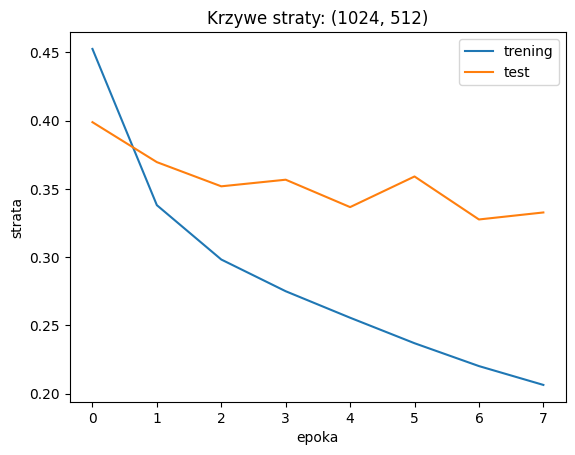

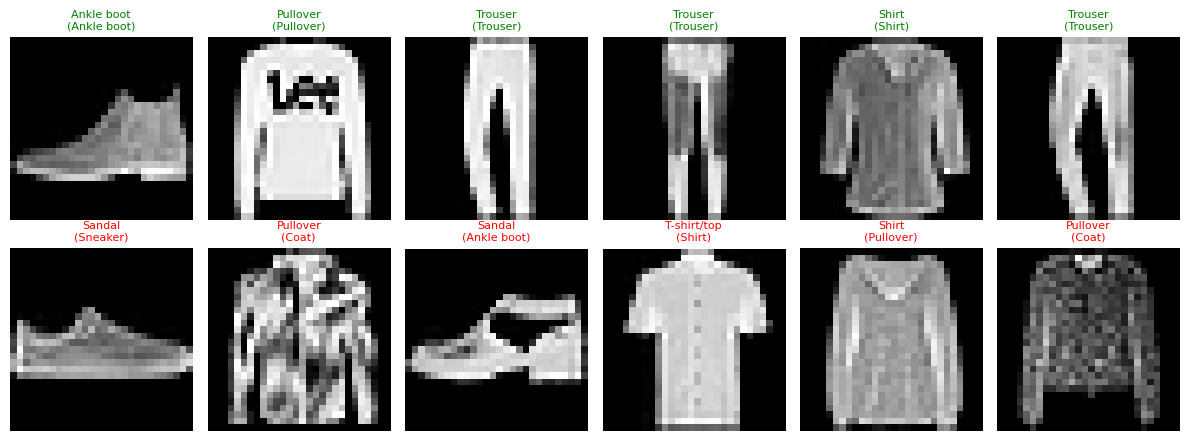

In [ ]:
best_name = max(results, key=lambda k: results[k]["acc"])
best = results[best_name]
model = best["model"].eval()

plt.plot(best["hist"]["train_loss"], label="trening")
plt.plot(best["hist"]["test_loss"], label="test")
plt.xlabel("epoka")
plt.ylabel("strata")
plt.title(f"Krzywe straty: {best_name}")
plt.legend()
plt.show()

preds, targets = [], []
with torch.no_grad():
    for xb, yb in test_dl:
        preds.append(model(xb.to(device)).argmax(1).cpu())
        targets.append(yb)
preds, targets = torch.cat(preds), torch.cat(targets)

ok_idx = (preds == targets).nonzero().flatten()[:6]
bad_idx = (preds != targets).nonzero().flatten()[:6]
idx = torch.cat([ok_idx, bad_idx])

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.flat, idx):
    img, _ = test_ds[i]
    ax.imshow(img.squeeze() * std + mean, cmap="gray")
    ok = preds[i] == targets[i]
    ax.set_title(f"{classes[preds[i]]}\n({classes[targets[i]]})",
                 fontsize=8, color="green" if ok else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Macierz pomyłek


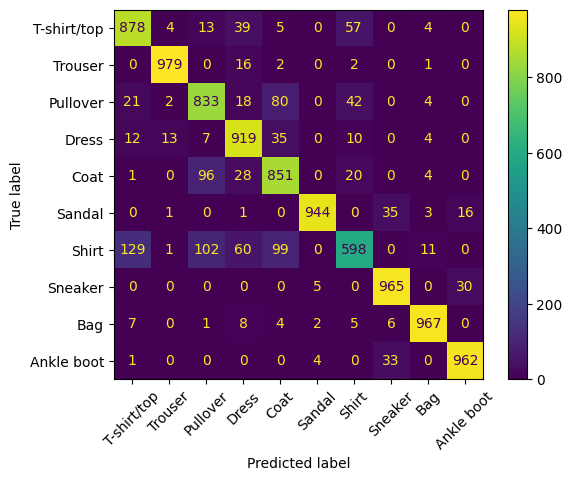

,klasa prawdziwa,klasa przewidziana,liczba pomyłek
0,Shirt,T-shirt/top,129
1,Shirt,Pullover,102
2,Shirt,Coat,99
3,Coat,Pullover,96
4,Pullover,Coat,80


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(targets, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(xticks_rotation=45)
plt.show()

off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
pairs = pd.DataFrame(
    [(classes[i], classes[j], int(off_diag[i, j]))
     for i in range(10) for j in range(10) if i != j],
    columns=["klasa prawdziwa", "klasa przewidziana", "liczba pomyłek"],
)
pairs.sort_values("liczba pomyłek", ascending=False).head(5).reset_index(drop=True)

### Wniosek

Najtrudniejszą parą klas jest Shirt i T-shirt/top: 129 koszul zostało rozpoznanych jako T-shirt/top, a 57 T-shirtów jako koszule. Klasa Shirt ma też najniższą skuteczność (598 z 1000, czyli 59,8%).